# Analysis of M5

In [112]:
import numpy as np
import math
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from photutils.psf import fit_fwhm

from matplotlib.patches import Rectangle

## Importing and Displaying Data for M5

In [161]:
# RA =  15:18:33.22
# Dec = +02:04:51.7

'''
data1, header1 = fits.getdata("cutout_229.6383_2.0808.fits", header=True)
data2, header2 = fits.getdata("cutout_229.6362_2.0609.fits", header=True)
data3, header3 = fits.getdata("cutout_229.6420_2.0902.fits", header=True)
'''

# cutout_229.6420_2.0902.fits has more of the cluster in frame
M5_data, M5_header = fits.getdata("cutout_229.6420_2.0902.fits", header=True)

In [101]:
print(M5_header)

SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                  -32 / number of bits per data pixel                  NAXIS   =                    3 / number of data axes                            NAXIS1  =                  256 / length of data axis 1                          NAXIS2  =                  256 / length of data axis 2                          NAXIS3  =                    3 / length of data axis 3                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H SURVEY  = 'LegacySurvey'                                                        VERSION = 'DR11    '                                                            IMAGETYP= 'IMAGE   '           / None                                           BANDS   = 'grz     '                    

In [86]:
#print(header1)

In [87]:
#print(header2)

In [89]:
#print(header3)

In [108]:
'''
# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.
M5_data_g = M5_data[0]
M5_data_r = M5_data[1]
M5_data_z = M5_data[2]
'''

'\n# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.\nM5_data_g = M5_data[0]\nM5_data_r = M5_data[1]\nM5_data_z = M5_data[2]\n'

In [109]:
# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.
M5_data_list = []

M5_band_list = ["g","r","z"]
for i in M5_data:
    M5_data_list.append(i)

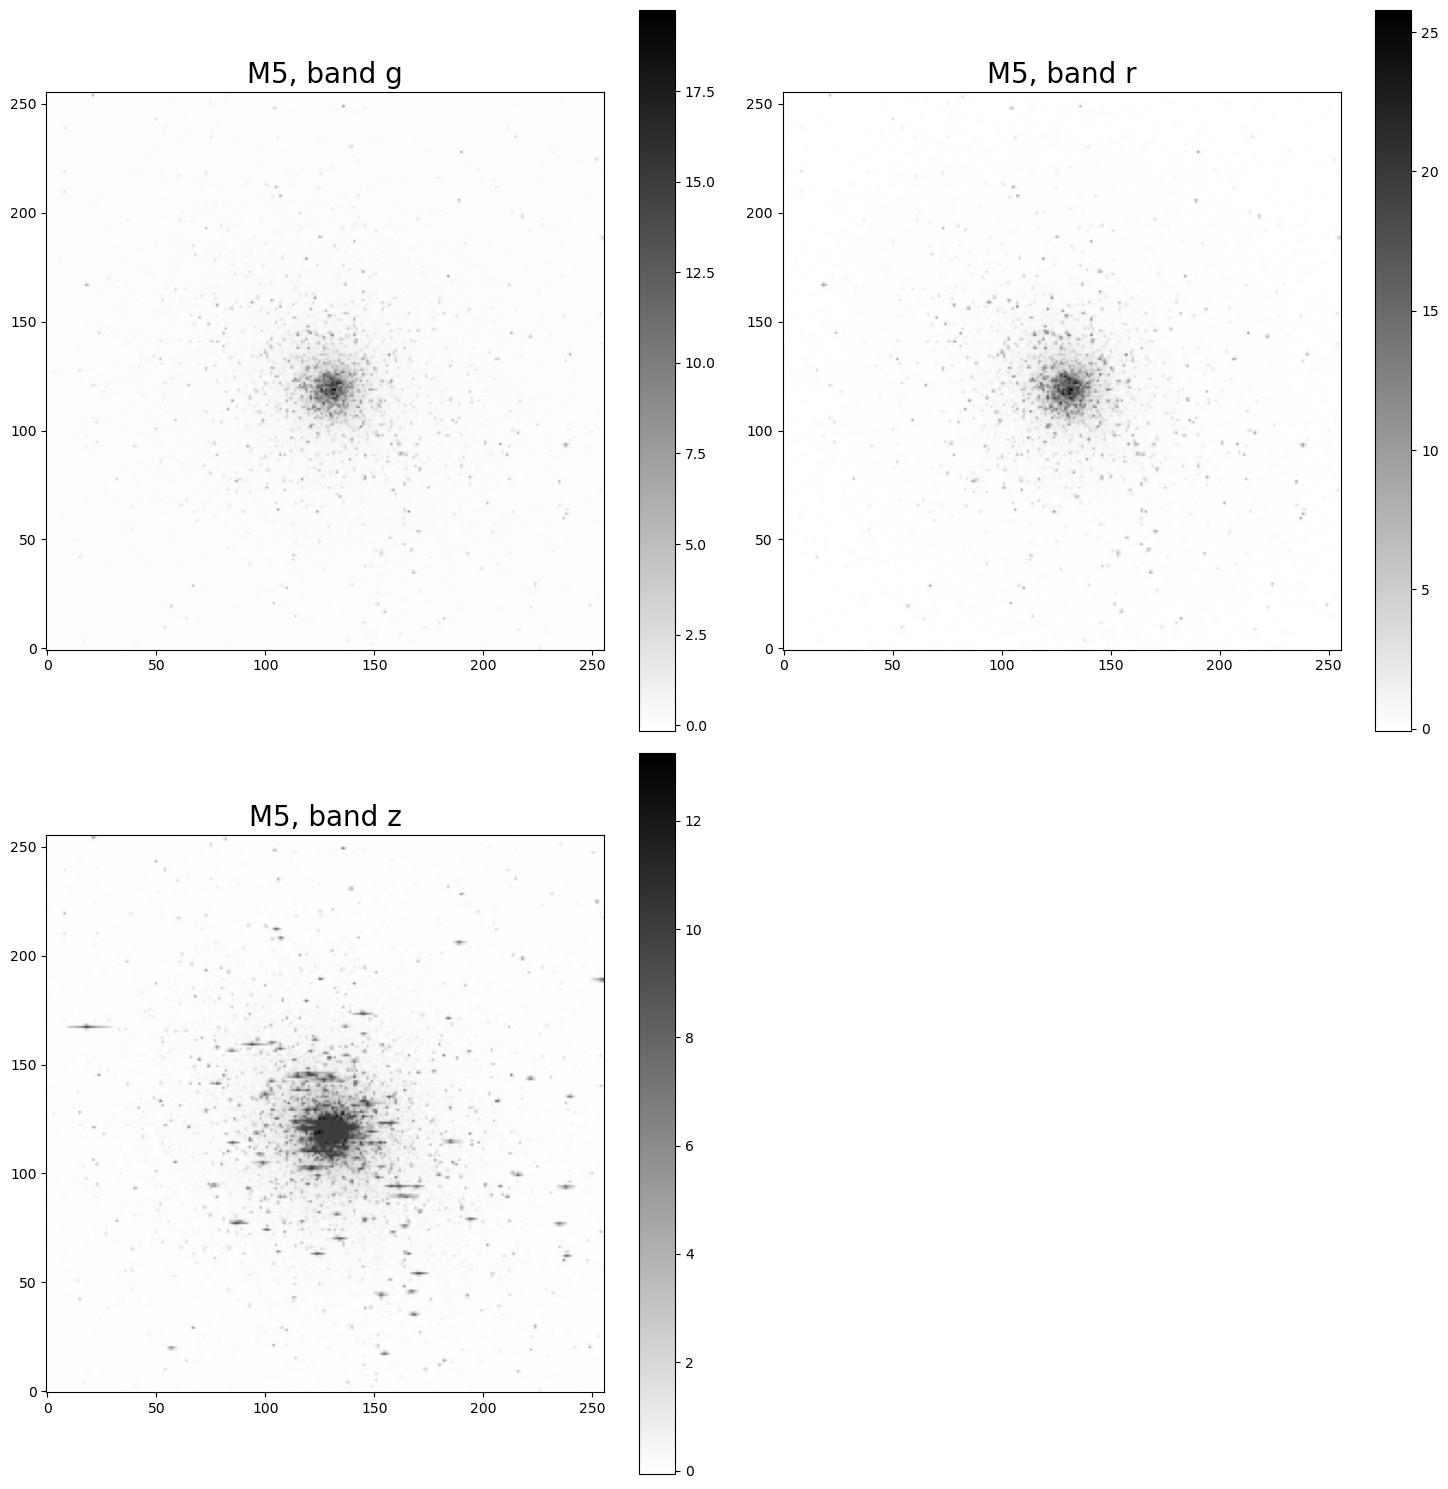

In [202]:
fig1 = plt.figure(1, figsize=(15,15))

for i in range(len(M5_data_list)):
    ax = plt.subplot(2,2,i+1)
    plt.imshow(M5_data_list[i], cmap="gray_r", origin="lower")
    plt.title(f"M5, band {M5_band_list[i]}", fontsize=20)
    plt.colorbar()
plt.tight_layout()

## Photometry

### Finding the outer stars

All images already have matching WCS.

To find the outer stars, first find the center of the cluster, then create increasingly large circles centered on that center and calculate the flux from within it to determine the cluster's profile.
From there, we can determine which radiative profile represents the outer stars.

### Removing Background
The corners can be used as an approximation of background. By subtracting that from the pixels in the image, we can remove the background.

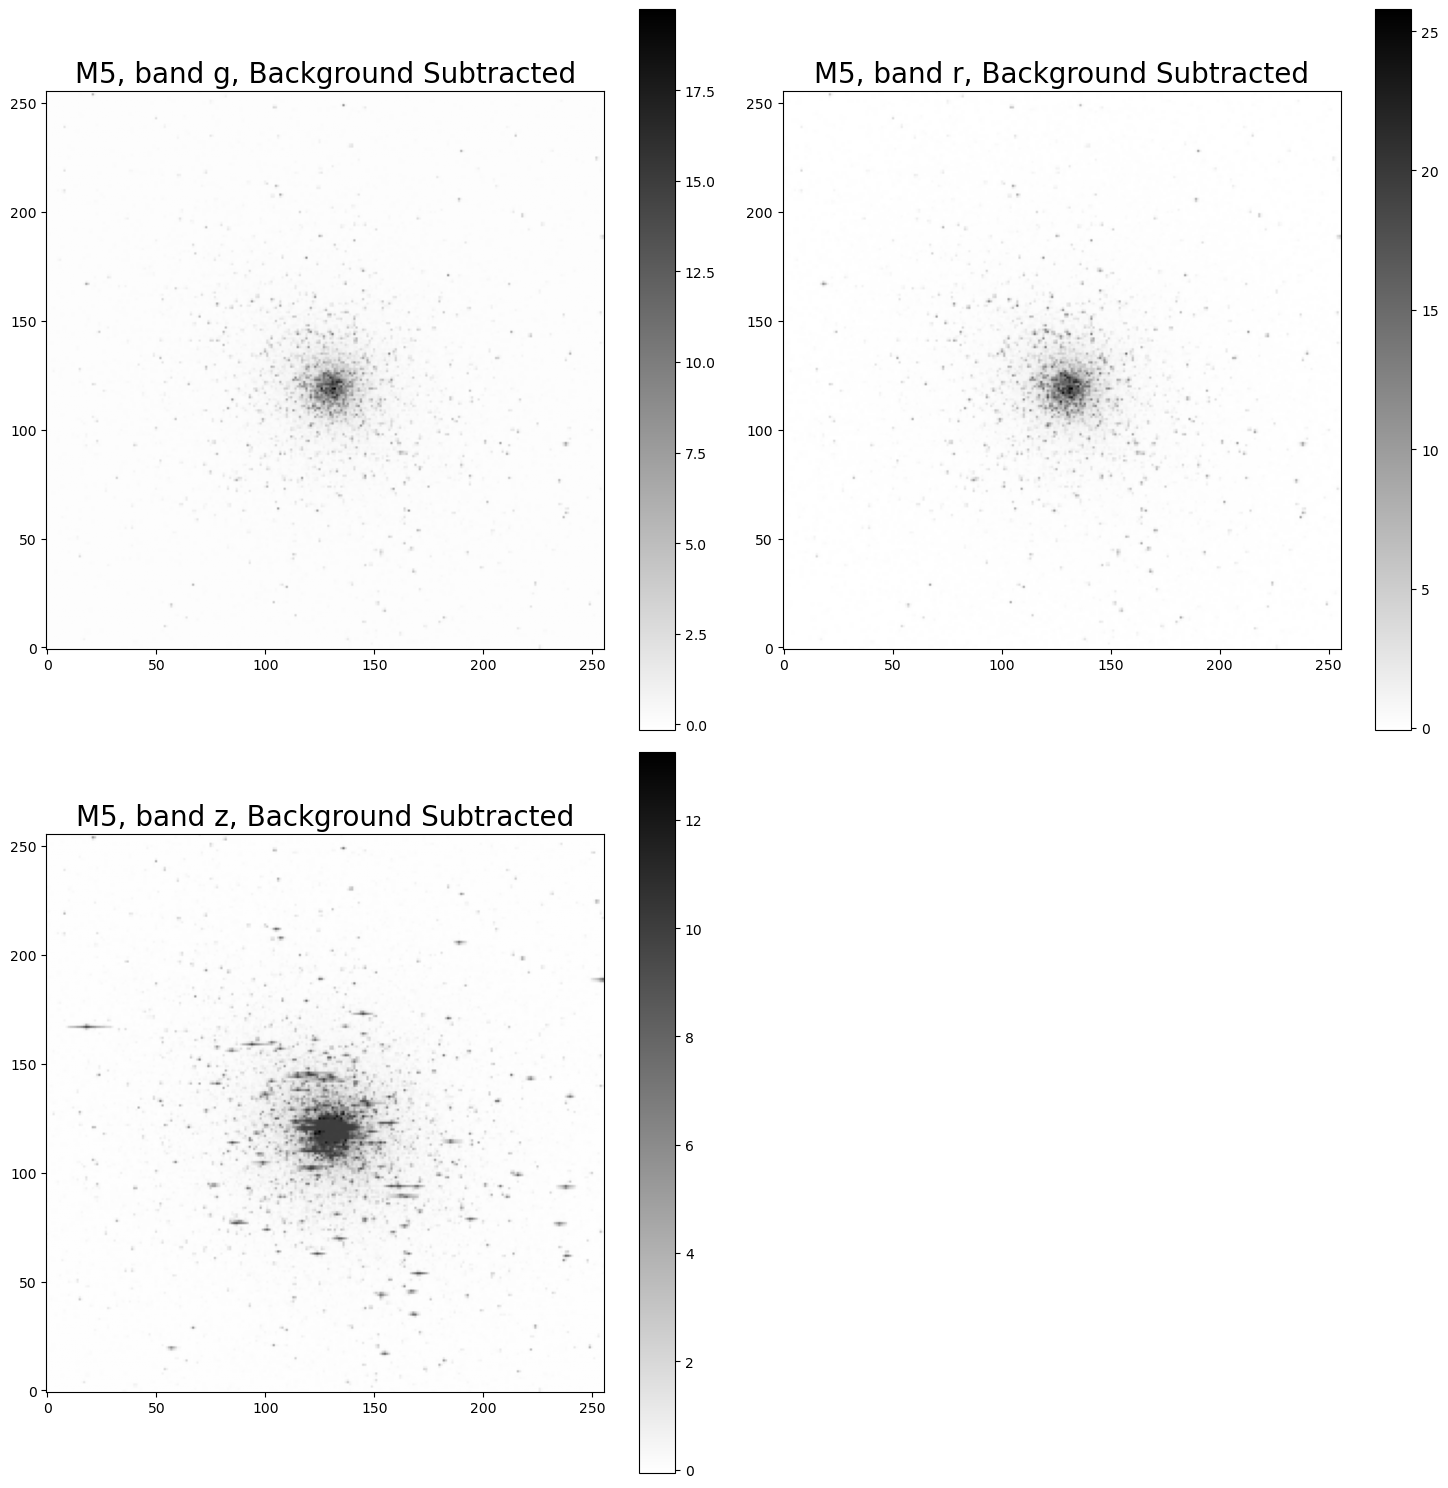

In [204]:
# Plotting the images with the squares for background subtraction
# Squares should be 40x40

fig2 = plt.figure(1, figsize=(15,15))

for i in range(len(M5_data_list)):
    # Squares should be 40x40
    M5_data_bkg = M5_data_list[i]
    UpperLeftSquare = M5_data_bkg[:40, :40]
    LowerRightSquare = M5_data_bkg[-40:, -40:]
    UpperRightSquare = M5_data_bkg[:40, -40:]
    LowerLeftSquare = M5_data_bkg[-40:, :40]
    M5_bkg = []
    M5_bkg.append(UpperLeftSquare)
    M5_bkg.append(LowerRightSquare)
    M5_bkg.append(UpperRightSquare)
    M5_bkg.append(LowerLeftSquare)
    M5_bkg_med = np.median(M5_bkg)
    M5_data_bsub = M5_data_bkg - M5_bkg_med
    
    ax = plt.subplot(2,2,i+1)
    plt.imshow(M5_data_bsub, cmap="gray_r", origin="lower")
    plt.title(f"M5, band {M5_band_list[i]}, Background Subtracted", fontsize=20)
    plt.colorbar()
plt.tight_layout()